# 1. Business hypothesis and experiment overview

| Item | Value |
|---|---|
| Experiment ID | `1.1_lightgbm_ranker` (traditional models track) |
| Owner | Nigel Yap |
| Model | LightGBM (binary click objective) on the shared engineered features |
| Stage | Stage 1: learn relevance on recorded slates, then shortlist the **time-eligible catalogue** (top 200 per request) |
| Export schema | v4 (`prediction_pool = time_eligible_catalogue`) |

**Business objective addressed.** *Relevant recommendations* (interim report s1.1, s1.2.3). Stage 1 must keep the articles a reader would click inside its 200-article shortlist, because the Stage 2 reranker can only reorder what Stage 1 keeps.

**Hypothesis.** Two kinds of information locate those articles: (a) **freshness**, since readers mostly click recently published articles, and (b) **personalisation**, meaning how closely an article's category, type and topics match the reader's history and recent reading. Gradient-boosted trees can combine such signals without scaling, and every one of them can be computed for an article that was never shown.

**Design consequences of scoring the whole catalogue.**
- The model is *trained* on the recorded slates (clicked = 1, shown and unclicked = 0), exactly as the shared protocol says, and *selected* by catalogue known-click **Recall@100**.
- Two shared features describe the recorded slate and are undefined for an article outside it: `slate_size` and `slate_relative_age_h`. They are **removed and the model is retrained** without them; the earlier recorded-slate-only run used them and is superseded (it stays a diagnostic result).
- All other features are rebuilt for any catalogue article with the shared definitions (`catalogue_v4.py`), and the rebuild is verified against the shared Parquet files in section 3.

**Validation evidence that would support the hypothesis** (section 6): the selection curve and objective trials; a targeted ablation (retrain without the freshness group, then without the personalisation group, and compare catalogue Recall@100); gain importance; and one explained recommendation.

# 2. Setup and run configuration

In [1]:
import os, sys, json, time, hashlib, platform, subprocess, pickle, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, lightgbm as lgb, pyarrow as pa, pyarrow.parquet as pq
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import catalogue_v4 as cv
warnings.filterwarnings("ignore", category=UserWarning)

EXPERIMENT_ID, OWNER, SEED, REQUEST_SEED = "1.1_lightgbm_ranker", "Nigel Yap", 42, 42
FEATURE_CASE = "raw"
RUN_ID = os.environ.get("BT4222_RUN_ID", "20261103_v4_seed42")
DEV_FRAC = float(os.environ.get("BT4222_DEV_FRAC", "0"))                 # >0: train on that fraction of COMPLETE recorded slates (smoke test only)
SELECTION_N = int(os.environ.get("BT4222_SEL_N", "200"))                # validation requests used to select the checkpoint/trial
EXPORT_N = {"train": int(os.environ.get("BT4222_EXPORT_N_TRAIN", "5000")),                       # requests per split exported with their full eligible catalogue
            "validation": int(os.environ.get("BT4222_EXPORT_N_VALIDATION", "0")),               # 0 = every request of the split
            "test": int(os.environ.get("BT4222_EXPORT_N_TEST", "0"))}
ROUNDS = int(os.environ.get("BT4222_ROUNDS", "400")); CHECK_EVERY = 25
SELECTION_K, EXPORT_K, FINAL_K = 100, 200, 5

# Colab: DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder")
DRIVE_ROOT = Path(os.environ.get("BT4222_DRIVE_ROOT", r"C:\Users\nigel\BT4222 Shared Final Folder"))
FEATURE_ROOT = DRIVE_ROOT / "feature_engineering"
SMALL_ROOT = Path(os.environ.get("BT4222_SMALL_ROOT", r"C:\Users\nigel\bt4222-data\ebnerd_small"))   # EB-NeRD small raw files
TEST_ARTICLES = os.environ.get("BT4222_TEST_ARTICLES")   # shared test catalogue (optional; needed for the shared union pool)
TEST_HISTORY = os.environ.get("BT4222_TEST_HISTORY")     # shared test history (needed to score test requests)
OUT = Path("outputs") / RUN_ID
PERSIST = Path(os.environ.get("BT4222_PERSIST_DIR", str(DRIVE_ROOT / "Experiments" / EXPERIMENT_ID / RUN_ID)))
for d in ["predictions/train", "predictions/validation", "predictions/test", "rankings/train", "rankings/validation",
          "rankings/test", "diagnostics/recorded_slates", "model", "tuning"]: (OUT / d).mkdir(parents=True, exist_ok=True)

NON_PREDICTORS = {"split","user_id","impression_id","candidate_article_id","current_page_article_id","impression_time","clicked"}
# Bounded, declared search: 3 settings, each trained for ROUNDS trees; the checkpoint (every CHECK_EVERY trees) with the
# highest validation catalogue Recall@100 is selected. Tie rule: higher nDCG@100, then the earlier trial/checkpoint.
BASE = dict(objective="binary", learning_rate=0.08, min_data_in_leaf=100, feature_fraction=0.7, bagging_fraction=0.8,
            bagging_freq=1, lambda_l2=1.0, max_bin=127, seed=SEED, verbosity=-1, deterministic=True, force_row_wise=True, metric="None",
            num_threads=int(os.environ.get("BT4222_THREADS", "0")))
TRIALS = {"leaves31": dict(num_leaves=31), "leaves63": dict(num_leaves=63), "leaves127": dict(num_leaves=127)}
def log(msg):
    line = time.strftime("%H:%M:%S ") + msg; print(line, flush=True)
    with open(OUT / "progress.log", "a", encoding="utf-8") as f: f.write(line + "\n")
print(f"run {RUN_ID} | selection requests {SELECTION_N} | export requests/split {EXPORT_N} (0 = all) | rounds {ROUNDS} | dev fraction {DEV_FRAC}")
log("start")

run 20261103_v4_seed42 | selection requests 200 | export requests/split {'train': 5000, 'validation': 0, 'test': 0} (0 = all) | rounds 400 | dev fraction 0.0
23:24:31 start


**Protocol.** Training uses the recorded slates only (no catalogue-wide negatives). Selection uses the first `SELECTION_N` validation requests in the shared deterministic hash order (blake2b of `seed:split:behaviour_id`, seed 42), each scored against its **full** time-eligible catalogue (`published_time <= impression_time`, policy `published_at_or_before_request_v1`, no age or embedding filter). Known-click Recall@100 is the primary metric and observed-click nDCG@100 the secondary one. Both are measured against *observed* clicks and treat unshown articles as unknown, not as negatives. Because validation is used for selection, its scores are **development results**. Test has no labels, so it is only scored.

In [2]:
def auc_by_slate(g, y, s):
    d = pd.DataFrame({"g": g, "y": y, "s": s}); d["r"] = d.groupby("g", sort=False)["s"].rank(method="average")
    a = d.assign(ry=d.r * d.y).groupby("g", sort=False).agg(n=("y","size"), pos=("y","sum"), ry=("ry","sum"))
    neg = a.n - a.pos; ok = (a.pos > 0) & (neg > 0)
    return ((a.ry - a.pos*(a.pos+1)/2) / (a.pos*neg))[ok].mean(), int(ok.sum()), int(len(a) - ok.sum())

def recorded_slate_metrics(g, y, s, k=5):
    """Diagnostic: mean impression AUC and nDCG@5 on the ORIGINAL shown candidates (ties get expected credit)."""
    g, y, s = np.asarray(g), np.asarray(y, dtype="float64"), np.asarray(s, dtype="float64")
    auc, n_auc, ex = auc_by_slate(g, y, s)
    d = pd.DataFrame({"g": g, "y": y, "s": s}); d["ty"] = d.groupby(["g","s"], sort=False)["y"].transform("mean")
    d = d.sort_values(["g","s"], ascending=[True, False], kind="stable"); d["pos"] = d.groupby("g", sort=False).cumcount() + 1
    dcg = (d.ty / np.log2(d.pos + 1)).where(d.pos <= k, 0).groupby(d.g, sort=False).sum()
    npos = d.groupby("g", sort=False)["y"].sum(); disc = np.r_[0, np.cumsum(1/np.log2(np.arange(1, k+1)+1))]
    ideal = pd.Series(disc[np.minimum(npos.to_numpy(), k).astype(int)], index=npos.index); ok = npos > 0
    return {"recorded_mean_impression_auc": float(auc), "recorded_ndcg@5": float((dcg[ok]/ideal[ok]).mean()),
            "impressions": int(d.g.nunique()), "candidate_rows": int(len(d)), "auc_eligible": n_auc, "auc_excluded_one_class": ex,
            "ndcg_excluded_no_positive": int((~ok).sum())}

# 3. Load and check shared data

In [3]:
state = json.load(open(FEATURE_ROOT / "feature_vocabulary.json", encoding="utf-8"))   # UTF-8: topic names contain Danish letters
data, FEATURES_ALL = {}, None
for sp in ["train", "validation", "test"]:
    path = FEATURE_ROOT / f"{sp}_features.parquet"
    names = pq.ParquetFile(path).schema_arrow.names
    feats = [c for c in names if c not in NON_PREDICTORS and not c.endswith("_log1p")]
    FEATURES_ALL = FEATURES_ALL or feats; assert feats == FEATURES_ALL, "feature order differs between splits"
    cols = ["user_id","impression_id","candidate_article_id","impression_time","is_subscriber","is_sso_user"] + \
           [c for c in feats if c not in ("is_subscriber","is_sso_user")] + (["clicked"] if sp != "test" else [])
    df = pd.read_parquet(path, columns=list(dict.fromkeys(cols)))
    assert not df.duplicated(["user_id","impression_id","candidate_article_id"]).any(), f"{sp}: duplicate candidate keys"
    df["behaviour_id"] = df.user_id.astype("int64").astype(str) + ":" + df.impression_id.astype("int64").astype(str)
    if DEV_FRAC > 0 and sp == "train":
        ids = df.behaviour_id.unique(); keep = set(np.random.default_rng(SEED).choice(ids, int(len(ids)*DEV_FRAC), replace=False))
        df = df[df.behaviour_id.isin(keep)]
    df["g"] = pd.factorize(df.behaviour_id)[0]
    data[sp] = df.sort_values("g", kind="stable").reset_index(drop=True)
    print(f"{sp:10s} rows={len(df):>9,} requests={df.g.nunique():>8,}" + (f" click_rate={df.clicked.mean():.4f}" if sp != "test" else " (unlabelled)"))
FEATURES = [c for c in FEATURES_ALL if c not in cv.POOL_DEPENDENT]
print(len(FEATURES_ALL), "shared predictors ->", len(FEATURES), "after removing", cv.POOL_DEPENDENT, "(undefined outside a slate)")

train      rows=2,585,747 requests= 232,887 click_rate=0.0904


validation rows=  344,666 requests=  29,110 click_rate=0.0849


test       rows=  446,915 requests=  29,085 (unlabelled)
202 shared predictors -> 200 after removing ['slate_size', 'slate_relative_age_h'] (undefined outside a slate)


In [4]:
# Catalogue: first source record wins; union with the shared test catalogue when it is available.
art_paths = [SMALL_ROOT / "articles.parquet"] + ([Path(TEST_ARTICLES)] if TEST_ARTICLES else [])
cat = cv.Catalogue(art_paths, state)
print(f"catalogue sources: {[str(p) for p in art_paths]}\narticles={cat.n:,} | topics={len(cat.topic_names)} | id fingerprint {cat.fingerprint}")
known_ids = set(cat.ids)
for sp in data: print(f"{sp:10s} recorded candidates found in catalogue: {data[sp].candidate_article_id.isin(known_ids).mean():.4f}")
HIST = {"train": SMALL_ROOT / "train" / "history.parquet", "validation": SMALL_ROOT / "validation" / "history.parquet",
        "test": Path(TEST_HISTORY) if TEST_HISTORY else None}
CATALOGUE_SCOPE = {"train": True, "validation": True, "test": bool(TEST_HISTORY)}
print("catalogue export possible:", CATALOGUE_SCOPE)

REQ = {}   # per split: requests in shared hash-priority order with their known clicks and request context
for sp in data:
    d = data[sp]
    first = d.drop_duplicates("behaviour_id").set_index("behaviour_id")
    reqs = cv.hash_order(first.reset_index()[["user_id","impression_id"]], sp, REQUEST_SEED)
    if sp != "test":
        known = d[d.clicked == 1].groupby("behaviour_id").candidate_article_id.apply(lambda s: set(s.astype("int64")))
        reqs["known"] = reqs.behaviour_id.map(known)
        reqs["known"] = reqs.known.map(lambda s: s if isinstance(s, set) else set())
    REQ[sp] = (reqs, first)
    print(f"{sp:10s} requests={len(reqs):,}" + (f" | requests with no known click: {(reqs.known.map(len)==0).sum()}" if sp != "test" else ""))

catalogue sources: ['C:\\Users\\nigel\\bt4222-data\\ebnerd_small\\articles.parquet']
articles=20,738 | topics=78 | id fingerprint eff069a2586ad6cd
train      recorded candidates found in catalogue: 1.0000
validation recorded candidates found in catalogue: 1.0000
test       recorded candidates found in catalogue: 0.9132
catalogue export possible: {'train': True, 'validation': True, 'test': False}


train      requests=232,887 | requests with no known click: 0


validation requests=29,110 | requests with no known click: 0


test       requests=29,085


In [5]:
PROFILES = {}
def ctx_of(sp, bid):
    r = REQ[sp][1].loc[bid]
    sub = r.is_subscriber
    c = {"impression_time": r.impression_time.to_datetime64(), "is_sso_user": float(r.is_sso_user) if pd.notna(r.is_sso_user) else np.nan,
         "is_subscriber": bool(sub) if pd.notna(sub) else float("nan"), "is_front_page": float(r.is_front_page),
         "hour": float(r.hour), "day_of_week": float(r.day_of_week)}
    c.update({k: float(r[k]) for k in r.index if k.startswith("ohe_device_type_")}); return c

def features_for(sp, bid, ix):
    r = REQ[sp][1].loc[bid]
    return cv.request_features(cat, PROFILES[(sp, int(r.user_id))], ctx_of(sp, bid), ix, FEATURES)

def need_profiles(sp, users):
    todo = [u for u in set(map(int, users)) if (sp, u) not in PROFILES]
    if todo:
        for u, p in cv.build_profiles(HIST[sp], todo, cat, state).items(): PROFILES[(sp, u)] = p

# Verification: rebuild the shared features for ORIGINAL recorded candidates and compare with the shared Parquet files.
verify = {}
for sp in ["train", "validation"]:
    reqs = REQ[sp][0].head(100); need_profiles(sp, reqs.user_id); bad, rows = {}, 0
    for b in reqs.behaviour_id:
        rec = data[sp][data[sp].behaviour_id == b]; ix = cat.pos.reindex(rec.candidate_article_id.to_numpy()).to_numpy(); ok = ~np.isnan(ix)
        Mx = features_for(sp, b, ix[ok].astype(int)); rows += int(ok.sum())
        for name, n_bad, mx in cv.compare_to_shared(rec[ok][FEATURES], Mx, FEATURES): bad[name] = bad.get(name, 0) + n_bad
    verify[sp] = dict(requests=len(reqs), rows_compared=rows, columns_compared=len(FEATURES), columns_with_mismatch=len(bad))
    print(sp, verify[sp])
assert all(v["columns_with_mismatch"] == 0 for v in verify.values()), "rebuilt features differ from the shared files"

train {'requests': 100, 'rows_compared': 1130, 'columns_compared': 200, 'columns_with_mismatch': 0}


validation {'requests': 100, 'rows_compared': 1058, 'columns_compared': 200, 'columns_with_mismatch': 0}


# 4. Prepare model inputs

In [6]:
# Trees take raw values and NaN natively: no imputation, scaling or other fitted transform, so nothing can leak from validation/test.
PREPROCESSING = {"feature_case": FEATURE_CASE, "features": FEATURES, "imputation": "none (LightGBM native NaN handling)", "scaling": "none",
                 "removed_pool_dependent_features": cv.POOL_DEPENDENT, "ids_and_target_excluded": sorted(NON_PREDICTORS)}
GROUPS = {"freshness": ["article_age_h", "article_age_missing", "is_24h_eligible"],
          "personalisation": [c for c in FEATURES if c.startswith(("hist_", "candidate_category_pref", "candidate_article_type_pref",
              "candidate_topic_pref", "category_affinity", "last5_mean_topic", "topic_affinity", "has_any_topic_overlap", "same_category_"))]}
print({k: len(v) for k, v in GROUPS.items()}); assert set(sum(GROUPS.values(), [])) <= set(FEATURES)
Xtr = data["train"][FEATURES].to_numpy("float32"); ytr = data["train"].clicked.to_numpy()

# Selection requests: first SELECTION_N validation requests in hash order; features for their FULL eligible catalogue are built once.
sel = REQ["validation"][0].head(SELECTION_N); need_profiles("validation", sel.user_id)
SEL = []
t0 = time.time()
for r in sel.itertuples():
    t = REQ["validation"][1].loc[r.behaviour_id].impression_time.to_datetime64(); ix = cat.eligible(t)
    SEL.append(dict(b=r.behaviour_id, ix=ix, ids=cat.ids[ix], M=features_for("validation", r.behaviour_id, ix), known=r.known))
print(f"{len(SEL)} selection requests | eligible pool: median {int(np.median([len(s['ix']) for s in SEL])):,}, max {max(len(s['ix']) for s in SEL):,} | built in {time.time()-t0:.0f}s")

{'freshness': 3, 'personalisation': 129}


200 selection requests | eligible pool: median 19,510, max 19,871 | built in 4s


# 5. Define and train model

In [7]:
def catalogue_eval(booster, reqs, n_iter, col_idx=None, ks=(100, 200)):
    """Macro-average over requests that have known clicks. Clicked articles that are ineligible stay in the denominator."""
    out, ties, elig_cov, empty = [], 0, [], 0
    for s in reqs:
        if not s["known"]: continue
        if len(s["ix"]) == 0: out.append({f"{m}@{k}": 0.0 for k in ks for m in ("recall", "ndcg")}); empty += 1; elig_cov.append(0.0); continue
        M = s["M"] if col_idx is None else s["M"][:, col_idx]
        sc = booster.predict(M, num_iteration=n_iter, raw_score=True)
        order, cross = cv.top_k(sc, s["ids"], EXPORT_K); ties += cross
        out.append(cv.retrieval_metrics(s["ids"][order], s["known"], ks))
        elig_cov.append(len(s["known"] & set(s["ids"])) / len(s["known"]))
    df = pd.DataFrame(out)
    return {**df.mean().to_dict(), "requests_with_known_clicks": len(df), "ties_crossing_cutoff": int(ties), "empty_pools": empty,
            "known_click_eligibility_coverage": float(np.mean(elig_cov))}

def fit(params, cols_idx=None, rounds=ROUNDS):
    X = Xtr if cols_idx is None else Xtr[:, cols_idx]
    return lgb.train({**BASE, **params}, lgb.Dataset(X, ytr, free_raw_data=False), rounds)

rows, boosters = [], {}
for name, p in TRIALS.items():
    t0 = time.time(); b = fit(p); boosters[name] = b
    for k in range(CHECK_EVERY, ROUNDS + 1, CHECK_EVERY):
        m = catalogue_eval(b, SEL, k); rows.append(dict(trial=name, checkpoint=k, **p, **m))
    best = max((r for r in rows if r["trial"] == name), key=lambda r: (r["recall@100"], r["ndcg@100"], -r["checkpoint"]))
    log(f"{name}: best checkpoint {best['checkpoint']} Recall@100={best['recall@100']:.4f} nDCG@100={best['ndcg@100']:.4f} ({time.time()-t0:.0f}s)")
trials = pd.DataFrame(rows); trials.to_csv(OUT / "tuning" / "trials.csv", index=False)
win = trials.assign(_t=trials.trial.map({n: i for i, n in enumerate(TRIALS)})).sort_values(
    ["recall@100", "ndcg@100", "_t", "checkpoint"], ascending=[False, False, True, True]).iloc[0]
CHOSEN, BEST_ITER = win.trial, int(win.checkpoint); booster = boosters[CHOSEN]
booster.save_model(str(OUT / "model" / "lightgbm_model.txt"), num_iteration=BEST_ITER)
print(f"\nSELECTED: {CHOSEN}, {BEST_ITER} trees | selection Recall@100={win['recall@100']:.4f}, nDCG@100={win['ndcg@100']:.4f}")

23:28:14 leaves31: best checkpoint 75 Recall@100=0.8600 nDCG@100=0.2300 (153s)


23:31:04 leaves63: best checkpoint 25 Recall@100=0.8400 nDCG@100=0.2203 (170s)


23:34:16 leaves127: best checkpoint 25 Recall@100=0.8350 nDCG@100=0.2138 (192s)



SELECTED: leaves31, 75 trees | selection Recall@100=0.8600, nDCG@100=0.2300


# 6. Validation results

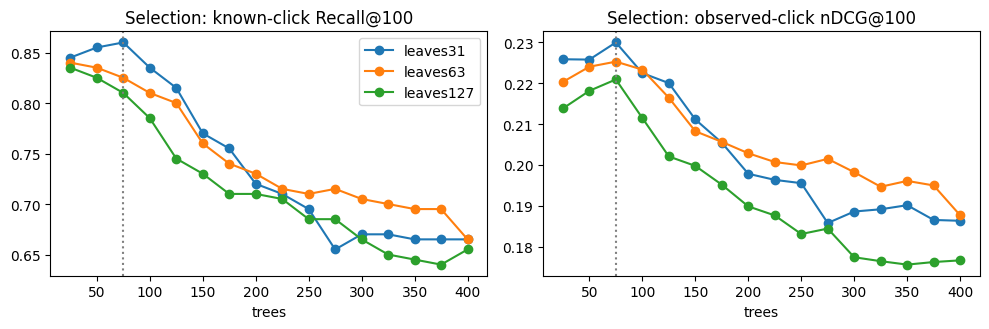

selected model on the selection requests (development result): {'recall@100': 0.86, 'ndcg@100': 0.23, 'recall@200': 0.915, 'ndcg@200': 0.2377, 'requests_with_known_clicks': 200, 'ties_crossing_cutoff': 73, 'empty_pools': 0, 'known_click_eligibility_coverage': 1.0}


,trial,checkpoint,num_leaves,recall@100,ndcg@100,recall@200,ndcg@200,requests_with_known_clicks,ties_crossing_cutoff,empty_pools,known_click_eligibility_coverage
3,leaves31,100,31,0.835,0.2225,0.895,0.2311,200,77,0,1.0
7,leaves31,200,31,0.720,0.1978,0.800,0.2090,200,68,0,1.0
11,leaves31,300,31,0.670,0.1886,0.730,0.1969,200,69,0,1.0
15,leaves31,400,31,0.665,0.1863,0.715,0.1932,200,77,0,1.0
19,leaves63,100,63,0.810,0.2234,0.850,0.2290,200,71,0,1.0
23,leaves63,200,63,0.730,0.2029,0.770,0.2084,200,64,0,1.0
27,leaves63,300,63,0.705,0.1982,0.770,0.2073,200,66,0,1.0
31,leaves63,400,63,0.665,0.1877,0.730,0.1969,200,52,0,1.0
35,leaves127,100,127,0.785,0.2115,0.840,0.2194,200,63,0,1.0
39,leaves127,200,127,0.710,0.1898,0.775,0.1992,200,39,0,1.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for n, g in trials.groupby("trial", sort=False):
    ax[0].plot(g.checkpoint, g["recall@100"], marker="o", label=n); ax[1].plot(g.checkpoint, g["ndcg@100"], marker="o", label=n)
ax[0].set_title("Selection: known-click Recall@100"); ax[1].set_title("Selection: observed-click nDCG@100")
for a in ax: a.set_xlabel("trees"); a.axvline(BEST_ITER, color="grey", ls=":")
ax[0].legend(); plt.tight_layout(); plt.show()
sel_metrics = catalogue_eval(booster, SEL, BEST_ITER)
print("selected model on the selection requests (development result):", {k: round(v, 4) if isinstance(v, float) else v for k, v in sel_metrics.items()})
trials[trials.checkpoint.isin([100, 200, 300, ROUNDS])].round(4)

In [9]:
# Diagnostic: recorded-slate AUC / nDCG@5 on the complete validation split (original shown candidates only).
Xv = data["validation"][FEATURES].to_numpy("float32")
sv = booster.predict(Xv, num_iteration=BEST_ITER, raw_score=True)
rec_val = recorded_slate_metrics(data["validation"].g.to_numpy(), data["validation"].clicked.to_numpy(), sv)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in rec_val.items()})

{'recorded_mean_impression_auc': 0.7176, 'recorded_ndcg@5': 0.5492, 'impressions': 29110, 'candidate_rows': 344666, 'auc_eligible': 29110, 'auc_excluded_one_class': 0, 'ndcg_excluded_no_positive': 0}


In [10]:
# Targeted ablation (same selected settings and selection requests): retrain without one feature group.
ABL = OUT / "tuning" / "ablation.csv"
rows = [dict(removed="none (full model)", n_features=len(FEATURES), **{k: sel_metrics[k] for k in ("recall@100", "ndcg@100", "recall@200")})]
for gname, gcols in GROUPS.items():
    keep_idx = [i for i, c in enumerate(FEATURES) if c not in set(gcols)]
    b = fit(TRIALS[CHOSEN], keep_idx); best = None
    for k in range(CHECK_EVERY, ROUNDS + 1, CHECK_EVERY):
        m = catalogue_eval(b, SEL, k, keep_idx)
        if best is None or (m["recall@100"], m["ndcg@100"]) > (best["recall@100"], best["ndcg@100"]): best = {**m, "k": k}
    rows.append(dict(removed=gname, n_features=len(keep_idx), **{k: best[k] for k in ("recall@100", "ndcg@100", "recall@200")}, best_trees=best["k"]))
abl = pd.DataFrame(rows); abl["d_recall@100"] = abl["recall@100"] - abl["recall@100"].iloc[0]; abl["d_ndcg@100"] = abl["ndcg@100"] - abl["ndcg@100"].iloc[0]
abl.to_csv(ABL, index=False); abl.round(4)

,removed,n_features,recall@100,ndcg@100,recall@200,best_trees,d_recall@100,d_ndcg@100
0,none (full model),200,0.8600,0.2300,0.9150,NaN,0.0000,0.0000
1,freshness,197,0.0375,0.0062,0.0575,125.0,-0.8225,-0.2238
2,personalisation,71,0.8950,0.2104,0.9400,25.0,0.0350,-0.0196


share of total gain: freshness 51.5% | personalisation 25.4% | other 23.1%


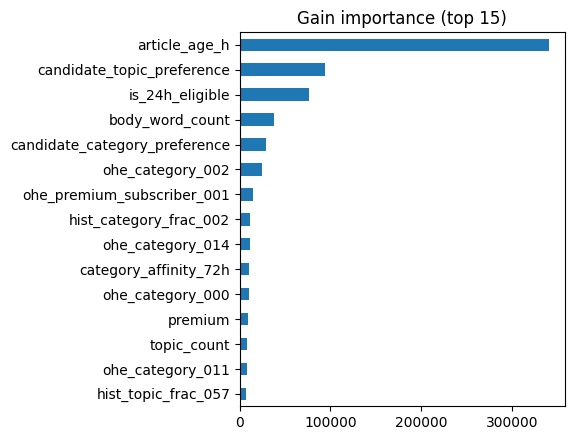

request 301029:242117638: 19,835 eligible articles; its known clicks [9790713]; ranks of known clicks in the top 200: [14]
top-ranked article 9789600 (score -0.97); biggest contributions:
                               contribution    value
article_age_h                         0.661    6.203
candidate_topic_preference            0.188    0.190
body_word_count                       0.174  106.000
candidate_category_preference         0.107    0.246
ohe_category_000                      0.098    0.000
is_24h_eligible                       0.097    1.000


In [11]:
gain = pd.Series(booster.feature_importance("gain", iteration=BEST_ITER), index=FEATURES).sort_values(ascending=False)
gain.to_csv(OUT / "tuning" / "gain_importance.csv", header=["gain"]); share = gain / gain.sum()
print("share of total gain: freshness %.1f%% | personalisation %.1f%% | other %.1f%%" % (100*share[GROUPS["freshness"]].sum(),
      100*share[GROUPS["personalisation"]].sum(), 100*share.drop(sum(GROUPS.values(), [])).sum()))
gain.head(15).iloc[::-1].plot.barh(figsize=(6, 4.5), title="Gain importance (top 15)"); plt.tight_layout(); plt.show()

# One explained recommendation: the top-ranked catalogue article for a selection request, with per-feature contributions.
s = next(s for s in SEL if s["known"] and len(s["ix"]) > 0)
sc = booster.predict(s["M"], num_iteration=BEST_ITER, raw_score=True); order, _ = cv.top_k(sc, s["ids"], EXPORT_K)
top1 = order[0]; contrib = booster.predict(s["M"][[top1]], num_iteration=BEST_ITER, pred_contrib=True)[0][:-1]
c = pd.Series(contrib, index=FEATURES); top = c.reindex(c.abs().sort_values(ascending=False).index).head(6)
print(f"request {s['b']}: {len(s['ix']):,} eligible articles; its known clicks {sorted(s['known'])}; "
      f"ranks of known clicks in the top 200: {[int(np.flatnonzero(s['ids'][order]==k)[0]+1) if k in s['ids'][order] else None for k in sorted(s['known'])]}")
print(f"top-ranked article {s['ids'][top1]} (score {sc[top1]:.2f}); biggest contributions:")
print(pd.DataFrame({"contribution": top.round(3), "value": pd.Series(s["M"][top1], index=FEATURES)[top.index].round(3)}).to_string())

**Reading the evidence (development results; numbers are from this run).**

- **Selected model.** `leaves31` at 75 trees: on the 200 validation selection requests Recall@100 = 0.860, nDCG@100 = 0.230, Recall@200 = 0.915. The other two settings reached 0.840 and 0.835 (both best at only 25 trees). With 200 requests the sampling error of a recall near 0.85 is about +/-0.025, so **the three settings are statistically hard to tell apart**; `leaves31` is chosen because the declared rule picks the highest Recall@100.
- **More trees made shortlisting worse.** For `leaves31`, Recall@100 falls from 0.860 (75 trees) to 0.665 (400 trees). The model is trained on recorded slates, where nearly all candidates are fresh, and a longer-trained model fits that task more tightly and transfers less well to a catalogue of about 19,500 mostly old articles. The grid checks every 25 trees, which is coarse when the best point is this early.
- **Selection was optimistic.** On the full validation export (29,110 requests, which include the 200 selection requests) the same model gets Recall@100 = 0.8275, nDCG@100 = 0.2169, Recall@200 = 0.9067. The 0.860 above is therefore best read as an upper estimate; report the full-validation figures as the development result.
- **Freshness is essential for shortlisting.** Retraining without the 3 freshness columns drops Recall@100 from 0.860 to 0.0375 (-0.82) on the same requests, because without any recency signal the model cannot separate the few recently published articles from about 19,000 older ones. Freshness also carries 51.5% of the total gain.
- **Personalisation did not improve shortlist membership.** Without the 129 history-preference columns Recall@100 was 0.895 (+0.035, inside the sampling error) and nDCG@100 fell by 0.020, so these features may help the *order* within the shortlist but there is **no evidence that they help decide which articles get in**. Part (b) of the hypothesis is therefore not supported for Recall@100 on this sample; a larger selection sample would be needed to be sure. They hold 25.4% of the gain.
- **Explained recommendation (section 6).** For request `301029:242117638` the known click ranked 14th of 19,835 eligible articles. The model's top article scored highly mainly through its age (6.2 h) and its match to the reader's topic history.
- **Limits.** Importances and contributions describe what the model uses, not what causes clicks; the ablations retrain on the same selection requests; recall and nDCG are measured against *observed* clicks and treat unshown articles as unknown, not negative.

# 7. Predict and export all splits

In [12]:
sig = lambda x: 1 / (1 + np.exp(-x))
def export_catalogue(sp, n):
    reqs = REQ[sp][0] if n == 0 else REQ[sp][0].head(n)
    need_profiles(sp, reqs.user_id); first = REQ[sp][1]
    bids, id_arrs, sc_arrs, man = [], [], [], []
    for i, r in enumerate(reqs.itertuples()):
        t = first.loc[r.behaviour_id].impression_time.to_datetime64(); ix = cat.eligible(t); ids = cat.ids[ix]
        if len(ix):
            sc = booster.predict(features_for(sp, r.behaviour_id, ix), num_iteration=BEST_ITER, raw_score=True)
            order, cross = cv.top_k(sc, ids, EXPORT_K)
        else: sc, order, cross = np.array([]), np.array([], int), False
        top_ids = ids[order]; bids.append(r.behaviour_id); id_arrs.append(top_ids.astype("int64")); sc_arrs.append(sc[order].astype("float64"))
        known = r.known if sp != "test" else set()
        man.append(dict(behaviour_id=r.behaviour_id, impression_time=t, eligible_pool=int(len(ix)), shortlist_len=int(len(top_ids)),
                        known_clicks=len(known), known_clicks_eligible=len(known & set(ids)) if known else 0, tie_at_cutoff=bool(cross)))
        if sp != "test" and known:
            man[-1].update(cv.retrieval_metrics(top_ids, known, (100, 200)) if len(top_ids) else {f"{m}@{k}": 0.0 for k in (100, 200) for m in ("recall", "ndcg")})
        if (i + 1) % 2000 == 0: log(f"{sp}: {i+1:,}/{len(reqs):,} requests exported")
    lens = np.array([len(a) for a in id_arrs])
    S = pd.DataFrame({"behaviour_id": np.repeat(np.array(bids, dtype=object), lens),
                      "article_id": np.concatenate(id_arrs) if len(id_arrs) else np.array([], "int64"),
                      "rank": np.concatenate([np.arange(1, l + 1) for l in lens]) if len(lens) else np.array([], int),
                      "score": np.concatenate(sc_arrs) if len(sc_arrs) else np.array([])})
    S["click_probability"] = sig(S.score.to_numpy())      # documented UNCALIBRATED sigmoid of the logit
    assert np.isfinite(S.score).all(), "non-finite scores"
    S.to_parquet(OUT / "predictions" / sp / "submission_article_scores.parquet", index=False, compression="zstd")
    pd.DataFrame({"behaviour_id": bids, "article_ids": [a.tolist() for a in id_arrs]}).to_parquet(
        OUT / "rankings" / sp / "submission_top_200.parquet", index=False, compression="zstd")
    m = pd.DataFrame(man); m.to_parquet(OUT / "predictions" / sp / "request_manifest.parquet", index=False)
    # integrity, read back from disk: one ranking row per request; ranking and score files agree on membership, order and length;
    # list length is min(200, pool size) (no padding); ranks are 1..len and scores are non-increasing within a request
    S2 = pd.read_parquet(OUT / "predictions" / sp / "submission_article_scores.parquet"); R2 = pd.read_parquet(OUT / "rankings" / sp / "submission_top_200.parquet")
    assert len(R2) == len(reqs) and R2.behaviour_id.is_unique, f"{sp}: ranking file must have exactly one row per request"
    assert (R2.article_ids.map(len).to_numpy() == np.minimum(EXPORT_K, m.eligible_pool.to_numpy())).all(), f"{sp}: shortlist is not min(200, pool)"
    flat = np.concatenate([np.asarray(a, dtype="int64") for a in R2.article_ids]) if len(R2) else np.array([], "int64")
    assert np.array_equal(flat, S2.article_id.to_numpy()), f"{sp}: score file and ranking file disagree on membership/order"
    assert not S2.duplicated(["behaviour_id", "article_id"]).any(), f"{sp}: duplicate (behaviour, article) keys"
    dec = S2.groupby("behaviour_id", sort=False).score.apply(lambda x: bool((np.diff(x.to_numpy()) <= 0).all())); assert dec.all(), f"{sp}: scores not descending"
    return m

exports, MAN = {}, {}
for sp in ["train", "validation", "test"]:
    if not CATALOGUE_SCOPE[sp]:
        print(f"{sp}: catalogue export NOT run (needs the shared test history; set BT4222_TEST_HISTORY and BT4222_TEST_ARTICLES)"); continue
    t0 = time.time(); MAN[sp] = export_catalogue(sp, EXPORT_N[sp])
    exports[sp] = dict(requests=len(MAN[sp]), score_rows=int(MAN[sp].shortlist_len.sum()), empty_pools=int((MAN[sp].eligible_pool == 0).sum()),
                       median_eligible_pool=float(MAN[sp].eligible_pool.median()), seconds=round(time.time() - t0))
    log(f"{sp}: exported {exports[sp]}")

23:41:20 train: 2,000/5,000 requests exported


23:42:36 train: 4,000/5,000 requests exported


23:43:17 train: exported {'requests': 5000, 'score_rows': 1000000, 'empty_pools': 0, 'median_eligible_pool': 18517.0, 'seconds': 201}


23:44:35 validation: 2,000/29,110 requests exported


23:45:52 validation: 4,000/29,110 requests exported


23:47:01 validation: 6,000/29,110 requests exported


... (9 outputs left out)

23:59:25 validation: 26,000/29,110 requests exported


00:00:45 validation: 28,000/29,110 requests exported


00:01:36 validation: exported {'requests': 29110, 'score_rows': 5822000, 'empty_pools': 0, 'median_eligible_pool': 19458.0, 'seconds': 1099}


test: catalogue export NOT run (needs the shared test history; set BT4222_TEST_HISTORY and BT4222_TEST_ARTICLES)


In [13]:
# Recorded-slate diagnostics: EVERY original candidate (including shown non-clicks), kept separate from the shortlists.
diag, rec_metrics = {}, {}
for sp in ["train", "validation", "test"]:
    d = data[sp]; s = booster.predict(d[FEATURES].to_numpy("float32"), num_iteration=BEST_ITER, raw_score=True)
    out = pd.DataFrame({"behaviour_id": d.behaviour_id.to_numpy(), "article_id": d.candidate_article_id.astype("int64").to_numpy(), "score": s,
                        "click_probability": sig(s)})
    out.sort_values(["behaviour_id", "article_id"]).to_parquet(OUT / "diagnostics" / "recorded_slates" / f"{sp}_scores.parquet", index=False, compression="zstd")
    diag[sp] = dict(rows=int(len(out)), requests=int(d.g.nunique()))
    if sp != "test": rec_metrics[sp] = recorded_slate_metrics(d.g.to_numpy(), d.clicked.to_numpy(), s)
    print(sp, diag[sp])
print("train metrics are IN-SAMPLE; test has no labels, so none is reported.")
pd.DataFrame(rec_metrics).T.round(4)

train {'rows': 2585747, 'requests': 232887}


validation {'rows': 344666, 'requests': 29110}


test {'rows': 446915, 'requests': 29085}
train metrics are IN-SAMPLE; test has no labels, so none is reported.


,recorded_mean_impression_auc,recorded_ndcg@5,impressions,candidate_rows,auc_eligible,auc_excluded_one_class,ndcg_excluded_no_positive
train,0.7451,0.5838,232887.0,2585747.0,232887.0,0.0,0.0
validation,0.7176,0.5492,29110.0,344666.0,29110.0,0.0,0.0


In [14]:
# Metrics on the exported requests (labelled splits): Recall@100/200 and observed-click nDCG@100/200 from the manifests.
exp_metrics = {}
for sp, m in MAN.items():
    if sp == "test": continue
    k = m[m.known_clicks > 0]
    exp_metrics[sp] = {c: float(k[c].mean()) for c in ("recall@100", "ndcg@100", "recall@200", "ndcg@200")}
    exp_metrics[sp].update(requests_with_known_clicks=int(len(k)), eligible_only_recall_denominator_share=float(k.known_clicks_eligible.sum() / k.known_clicks.sum()),
                           ties_at_cutoff=int(m.tie_at_cutoff.sum()))
pd.DataFrame(exp_metrics).T.round(4)

,recall@100,ndcg@100,recall@200,ndcg@200,requests_with_known_clicks,eligible_only_recall_denominator_share,ties_at_cutoff
train,0.8795,0.2339,0.9416,0.2427,5000.0,0.9996,1463.0
validation,0.8275,0.2169,0.9067,0.2281,29110.0,1.0000,9184.0


In [15]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def git(*a):
    try: return subprocess.run(["git", *a], capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception: return "unavailable"
inputs = {sp: dict(path=str(FEATURE_ROOT / f"{sp}_features.parquet"), sha256=sha256(FEATURE_ROOT / f"{sp}_features.parquet"), recorded_rows=diag[sp]["rows"]) for sp in data}
inputs["articles"] = [dict(path=str(p), size_bytes=p.stat().st_size) for p in art_paths]
inputs["history"] = {k: (dict(path=str(v), size_bytes=v.stat().st_size) if v else None) for k, v in HIST.items()}
run_config = dict(experiment_id=EXPERIMENT_ID, run_id=RUN_ID, owner=OWNER, seed=SEED, request_sampling_seed=REQUEST_SEED, export_schema_version=4,
    prediction_pool="time_eligible_catalogue", selection_k=SELECTION_K, export_k=EXPORT_K, shortlist_size=EXPORT_K, final_display_size=FINAL_K,
    scope=dict(selection_requests=len(SEL), export_requests_per_split=EXPORT_N, export_requests_actual={k: v['requests'] for k, v in exports.items()}, catalogue_export_run=CATALOGUE_SCOPE, training="all recorded candidate rows of the train split" if DEV_FRAC == 0 else f"DEV sample {DEV_FRAC}",
               sampled_run=True, note="sampled development run: every selected request uses its FULL eligible catalogue; this is not a full-split export"),
    eligibility=dict(policy=cv.POLICY, rule="known published_time <= impression_time; no age/access cutoff; no embedding filter", catalogue_articles=cat.n,
                     catalogue_fingerprint=cat.fingerprint, sources=[str(p) for p in art_paths],
                     pool_variant="train_val catalogue only" if not TEST_ARTICLES else "train_val + test union (shared policy)"),
    selection=dict(primary="mean known-click Recall@100 (maximise)", secondary="mean observed-click nDCG@100", tie_rule="higher nDCG@100, then earlier trial/checkpoint",
                   partition="validation selection requests (development results)", trials=list(TRIALS), rounds=ROUNDS, checkpoint_every=CHECK_EVERY,
                   selected_trial=CHOSEN, selected_trees=BEST_ITER),
    hyperparameters={**BASE, **TRIALS[CHOSEN]}, training_objective="binary click prediction on recorded pairs (shown and unclicked = 0; catalogue articles are never labelled 0)",
    score_semantics=dict(score_type="logit", click_probability="sigmoid(score), documented UNCALIBRATED estimate", source="LightGBM raw_score"),
    features=FEATURES, n_features=len(FEATURES), removed_features=cv.POOL_DEPENDENT, preprocessing=PREPROCESSING["imputation"],
    feature_rebuild_verification=verify, inputs=inputs, exports=exports, recorded_slate_diagnostics=diag, test_labels="unavailable (not evaluated)",
    packages=dict(python=platform.python_version(), lightgbm=lgb.__version__, pandas=pd.__version__, numpy=np.__version__),
    code_commit=git("rev-parse", "HEAD"), uncommitted_changes=bool(git("status", "--porcelain")), persistent_artifact_location=str(PERSIST))
(OUT / "run_config.json").write_text(json.dumps(run_config, indent=2, default=str))
(OUT / "metrics.json").write_text(json.dumps(dict(
    note="development/validation results: validation selection requests were used to pick the trial and tree count; test has no labels",
    primary="known-click Recall@100", secondary="observed-click nDCG@100", selection_validation=sel_metrics, exported_requests=exp_metrics,
    recorded_slate_diagnostic=rec_metrics, ablation=json.loads(abl.to_json(orient="records")), trials_best_per_trial=json.loads(
        trials.sort_values(["recall@100", "ndcg@100"], ascending=False).groupby("trial").head(1).to_json(orient="records"))), indent=2, default=str))
pickle.dump(PREPROCESSING, open(OUT / "model" / "preprocessing.pkl", "wb"))
(OUT / "model" / "model_config.json").write_text(json.dumps(dict(library="lightgbm", model_file="lightgbm_model.txt", objective="binary (logit scores)",
    num_iteration=BEST_ITER, feature_names=FEATURES, catalogue_feature_code="catalogue_v4.py (Catalogue, build_profiles, request_features)",
    shared_vocabulary="feature_engineering/feature_vocabulary.json (read as UTF-8)", eligibility=cv.POLICY), indent=2))
(OUT / "requirements.txt").write_text(f"lightgbm=={lgb.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\npyarrow\nscipy\nmatplotlib\n")
shutil.copy("catalogue_v4.py", OUT / "model" / "catalogue_v4.py")
print("saved run bundle to", OUT.resolve())

saved run bundle to C:\Users\nigel\bt4222-repo\Experiments\1.1_lightgbm_ranker\outputs\20261103_v4_seed42


# 8. Reload check

In [16]:
# Copy the complete run to the persistent location, then reload from THAT copy without retraining and compare with the export.
if PERSIST.resolve() != OUT.resolve(): shutil.copytree(OUT, PERSIST, dirs_exist_ok=True)
rl = lgb.Booster(model_file=str(PERSIST / "model" / "lightgbm_model.txt"))
pre = pickle.load(open(PERSIST / "model" / "preprocessing.pkl", "rb")); assert pre["features"] == FEATURES
exported = pd.read_parquet(PERSIST / "predictions" / "validation" / "submission_article_scores.parquet")
probe = REQ["validation"][0].head(5).behaviour_id.tolist(); worst = 0.0; n = 0
for b in probe:
    t = REQ["validation"][1].loc[b].impression_time.to_datetime64(); ix = cat.eligible(t)
    sc = rl.predict(features_for("validation", b, ix), raw_score=True)
    ref = exported[exported.behaviour_id == b].set_index("article_id").score
    mine = pd.Series(sc, index=cat.ids[ix]).reindex(ref.index)
    worst = max(worst, float(np.abs(mine.to_numpy() - ref.to_numpy()).max())); n += len(ref)
TOL = 1e-6
print(f"reloaded from {PERSIST}\n{len(probe)} requests / {n} exported scores compared | max abs difference = {worst:.2e} | tolerance {TOL:.0e}")
assert worst < TOL, "reload check FAILED"
need = ["lightgbm_model.txt", "preprocessing.pkl", "model_config.json", "catalogue_v4.py"]
assert all((PERSIST / "model" / f).exists() for f in need), "persistent model bundle incomplete"
print("RELOAD CHECK PASSED (numerical probe on the persistent copy; file hashes were not compared)")

reloaded from C:\Users\nigel\BT4222 Shared Final Folder\Experiments\1.1_lightgbm_ranker\20261103_v4_seed42
5 requests / 1000 exported scores compared | max abs difference = 0.00e+00 | tolerance 1e-06
RELOAD CHECK PASSED (numerical probe on the persistent copy; file hashes were not compared)


# 9. Business interpretation and handoff

In [17]:
print(f"Selected: {CHOSEN}, {BEST_ITER} trees. Development results on {len(SEL)} validation selection requests (full eligible catalogue): "
      f"Recall@100 = {sel_metrics['recall@100']:.4f}, nDCG@100 = {sel_metrics['ndcg@100']:.4f}, Recall@200 = {sel_metrics['recall@200']:.4f}.")
print("Bundle (local):", OUT.resolve()); print("Bundle (persistent copy):", PERSIST.resolve())

Selected: leaves31, 75 trees. Development results on 200 validation selection requests (full eligible catalogue): Recall@100 = 0.8600, nDCG@100 = 0.2300, Recall@200 = 0.9150.
Bundle (local): C:\Users\nigel\bt4222-repo\Experiments\1.1_lightgbm_ranker\outputs\20261103_v4_seed42
Bundle (persistent copy): C:\Users\nigel\BT4222 Shared Final Folder\Experiments\1.1_lightgbm_ranker\20261103_v4_seed42


**Finding.** A LightGBM click model trained on recorded slates and selected by catalogue Recall@100 keeps **82.8% of a reader's known clicks inside its top 100, and 90.7% inside its top 200**, out of about 19,500 time-eligible articles per request (full validation, 29,110 requests; development results, nDCG@100 = 0.217, nDCG@200 = 0.228). In-sample on 5,000 train requests the same figures are 0.880 and 0.942, so the shortlist generalises reasonably.

**Relation to the business objective.** Stage 1 protects *relevance*: 9.3% of known validation clicks (2,722 of 29,249) fall outside the top 200, and Stage 2 cannot recover them, so the reranker's final top 5 should be compared with Stage 1's top 5 on observed clicks. Freshness is the dominant signal, so the shortlist is already biased towards new articles; the reranker's freshness objective will have little to add, and its diversity objective is the more useful lever. Offline clicks are an engagement proxy and do not by themselves show retention.

**Diagnostic on the original shown candidates.** The recorded-slate mean impression AUC is 0.7176 (nDCG@5 = 0.5492), against 0.7561 (0.5935) for the earlier recorded-slate-only run. The difference is the cost of removing `slate_size` and `slate_relative_age_h`, which are undefined for articles outside a slate. That earlier run is superseded and remains only a diagnostic result.

**Limitations.**
- **Sampled scope.** Training used all recorded rows, but the catalogue export covers 5,000 train requests and all 29,110 validation requests. **The test catalogue export was not run**: it needs the shared test `articles.parquet` and `history.parquet`. Recorded-slate scores for test are provided.
- **Pool.** Eligibility is `published_at_or_before_request_v1` over the small train/validation catalogue (20,738 articles, fingerprint `eff069a2586ad6cd`), not the shared train/validation + test union, so the pool fingerprint will differ from 3.1's.
- **Ties.** In 31.5% of validation requests (9,184 of 29,110) two or more articles share the score at rank 200; the tie rule (ascending article ID) is deterministic but arbitrary.
- **Selection.** The checkpoint and setting were chosen on 200 validation requests, so validation numbers are development results and the three settings are not clearly distinguishable. Personalisation's contribution is unresolved.
- **Reproducibility.** The code was not committed when the run executed (`uncommitted_changes = true` in `run_config.json`). Hashes were not compared during the reload check, which was a numerical probe.

**Handoff.** Bundle: `Experiments/1.1_lightgbm_ranker/outputs/20261103_v4_seed42/` (persistent copy in the shared folder). `predictions/{train,validation}/submission_article_scores.parquet` (`behaviour_id, article_id, rank, score, click_probability`; `score` is a logit and `click_probability` an uncalibrated sigmoid), `rankings/{train,validation}/submission_top_200.parquet`, `predictions/{split}/request_manifest.parquet` (pool sizes, known-click counts, per-request metrics), `diagnostics/recorded_slates/{train,validation,test}_scores.parquet`, `model/` (LightGBM text model, `preprocessing.pkl`, `model_config.json` and `catalogue_v4.py` for rebuilding catalogue features), `metrics.json`, `run_config.json` (`export_schema_version = 4`, `selection_k = 100`, `export_k = 200`) and `tuning/`. The reload check from the persistent copy matched the exported scores exactly.